Just a simple cell to check if everything is well installed 

In [ ]:
import sys
import pandas as pd
import numpy as np
import duckdb
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pyarrow
import openpyxl
import mlxtend
import ucimlrepo

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("duckdb:", duckdb.__version__)
print("requests:", requests.__version__)
print("beautifulsoup4: OK")
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("pyarrow:", pyarrow.__version__)
print("openpyxl:", openpyxl.__version__)
print("mlxtend:", mlxtend.__version__)
print("ucimlrepo: OK")

## Acquisition strategy


The acquisition has two stages:

1. `/discover/movie` is used to retrieve movies matching the registered scope:
   - release date: 2020-01-01 to 2025-12-31
   - origin country: US
   - genre: Drama OR Thriller
   - minimum vote count: 100

2. `/movie/{movie_id}/credits` is queried for every selected movie to retrieve:
   - director(s)
   - producer(s)
   - cinematographer(s)
   - top-6 billed actors


In [1]:
import os
import json
import time
import random
import hashlib
from pathlib import Path
from email.utils import parsedate_to_datetime
from datetime import datetime, timezone

import requests
import pandas as pd

from dotenv import load_dotenv

load_dotenv()

URL = "https://api.themoviedb.org/3"
DISCOVER = f"{URL}/discover/movie"

TMDB_TOKEN = os.getenv("TMDB_TOKEN")

assert TMDB_TOKEN, "TMDB_TOKEN is missing from .env"

HEADERS = {
    "Authorization": f"Bearer {TMDB_TOKEN}",
    "Accept": "application/json"
}

CACHE = Path("cache")
CACHE.mkdir(exist_ok=True)


print("TMDB credentials loaded ")
print("Token available:", bool(TMDB_TOKEN))
print("Token length:", len(TMDB_TOKEN))

TMDB credentials loaded 
Token available: True
Token length: 239


In [2]:
PARAMS = {
    "primary_release_date.gte": "2020-01-01",
    "primary_release_date.lte": "2025-12-31",
    "with_origin_country": "US",
    "with_genres": "18|53",
    "vote_count.gte": 100,
    "include_adult": "false",
    "include_video": "false",
    "language": "en-US"
}

def cache_key(url, params=None):
    payload = url + "|" + json.dumps(params or {}, sort_keys=True)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]

def http_get(url, params=None, headers=HEADERS, attempts=5):
    for k in range(attempts):

        try:
            r = requests.get(url,params=params,headers=headers,timeout=10)

        except requests.RequestException as exc:
            status, retry_after = repr(exc), 0

        else:

            if r.status_code == 200:
                return r.json()

            if r.status_code not in (429, 500, 502, 503, 504):
                r.raise_for_status()

            # Temporary error -> retry
            status = r.status_code

            try:
                retry_after = int(r.headers.get("Retry-After", 0))
            except ValueError:
                retry_after = 0

        if k + 1 < attempts:
            wait = retry_after or random.uniform(0.001, 2**k)

            print(
                f"{status} on attempt {k + 1}, "
                f"sleeping {wait:.1f}s"
            )

            time.sleep(wait)

    raise RuntimeError(
        f"gave up after {attempts} attempts: {url}"
    )


def cached_get(url, params=None):
    path = CACHE / f"{cache_key(url, params)}.json"

    timestart = datetime.now(timezone.utc)
    if path.exists():
        return json.loads(path.read_text())

    body = http_get(url, params)
    timeend = datetime.now(timezone.utc)

    path.write_text(
        json.dumps(body)
    )

    return body

In [3]:
## test if it works 
params = PARAMS.copy()
params["page"] = 1



payload = cached_get(
    DISCOVER,
    params
)


print("page:", payload["page"])
print("total pages:", payload["total_pages"])
print("total results:", payload["total_results"])
print("results on page:", len(payload["results"]))


page: 1
total pages: 61
total results: 1208
results on page: 20


In [4]:
##getting all movies from the API

movies = []
page = 1
total_pages = None

timestart = datetime.now(timezone.utc)
while True:

    params = PARAMS.copy()
    params["page"] = page

    payload = cached_get(
        DISCOVER,
        params
    )

    movies += payload["results"]

    if total_pages is None:
        total_pages = payload["total_pages"]

    print(
        f"page {page}/{total_pages} "
        f"- {len(movies)} movies"
    )

    if page >= total_pages:
        break

    page += 1

timeend = datetime.now(timezone.utc)
print("time start:", timestart)
print("time end:", timeend)



page 1/61 - 20 movies
page 2/61 - 40 movies
page 3/61 - 60 movies
page 4/61 - 80 movies
page 5/61 - 100 movies
page 6/61 - 120 movies
page 7/61 - 140 movies
page 8/61 - 160 movies
page 9/61 - 180 movies
page 10/61 - 200 movies
page 11/61 - 220 movies
page 12/61 - 240 movies
page 13/61 - 260 movies
page 14/61 - 280 movies
page 15/61 - 300 movies
page 16/61 - 320 movies
page 17/61 - 340 movies
page 18/61 - 360 movies
page 19/61 - 380 movies
page 20/61 - 400 movies
page 21/61 - 420 movies
page 22/61 - 440 movies
page 23/61 - 460 movies
page 24/61 - 480 movies
page 25/61 - 500 movies
page 26/61 - 520 movies
page 27/61 - 540 movies
page 28/61 - 560 movies
page 29/61 - 580 movies
page 30/61 - 600 movies
page 31/61 - 620 movies
page 32/61 - 640 movies
page 33/61 - 660 movies
page 34/61 - 680 movies
page 35/61 - 700 movies
page 36/61 - 720 movies
page 37/61 - 740 movies
page 38/61 - 760 movies
page 39/61 - 780 movies
page 40/61 - 800 movies
page 41/61 - 820 movies
page 42/61 - 840 movies
page 

In [5]:
##normalize the data 
movie_columns = [
    "id",
    "title",
    "original_title",
    "release_date",
    "genre_ids",
    "original_language",
    "vote_count",
    "vote_average",
    "popularity"
]

movies_df = pd.json_normalize(movies) ## all the distinct movies in the dataset
movies_df = movies_df[movie_columns]
movies_genre = movies_df.explode("genre_ids") ## (movie, genre) per row


movies_genre

,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity
0,755898,War of the Worlds,War of the Worlds,2025-07-29,878,en,1160,4.034,107.0445
0,755898,War of the Worlds,War of the Worlds,2025-07-29,53,en,1160,4.034,107.0445
1,591634,False Positive,False Positive,2021-06-18,27,en,204,5.556,49.4602
1,591634,False Positive,False Positive,2021-06-18,9648,en,204,5.556,49.4602
1,591634,False Positive,False Positive,2021-06-18,53,en,204,5.556,49.4602
...,...,...,...,...,...,...,...,...,...
1205,848278,Jurassic Hunt,Jurassic Hunt,2021-08-26,53,en,221,5.000,1.3992
1205,848278,Jurassic Hunt,Jurassic Hunt,2021-08-26,27,en,221,5.000,1.3992
1206,586032,1,1,2020-09-14,18,en,118,6.700,1.1651
1207,715658,The Scientist,The Scientist,2020-09-21,27,en,111,6.000,1.3260


In [6]:

CREDITS_PARAMS = {
    "language": "en-US"
}

JOBS = {
    "Director": "director",
    "Producer": "producer",
    "Director of Photography": "cinematographer"
}

credits_element= []
timestartC = datetime.now(timezone.utc)
for movie_id in movies_df["id"].unique():

    credits_url = f"{URL}/movie/{movie_id}/credits"

    credits = cached_get(credits_url,CREDITS_PARAMS)

    for person in credits["crew"]:

        if person["job"] in JOBS:

            credits_element.append({
                "movie_id": movie_id,
                "person_id": person["id"],
                "person_name": person["name"],
                "role": JOBS[person["job"]],
                "department": person["department"],
                "job": person["job"],
                "billing_order": None
            })


    top_actors = sorted(credits["cast"],key=lambda actor: actor["order"])[:6]

    for actor in top_actors:

        credits_element.append({
            "movie_id": movie_id,
            "person_id": actor["id"],
            "person_name": actor["name"],
            "role": "actor",
            "department": None,
            "job": None,
            "billing_order": actor["order"]
        })

timeendC = datetime.now(timezone.utc)
print("time start:", timestartC)
print("time end:", timeendC)

time start: 2026-10-20 13:46:29.110725+00:00
time end: 2026-10-20 13:46:29.737055+00:00


In [7]:
credits_df = pd.json_normalize(credits_element)
print("Credits DataFrame shape:", credits_df.shape)

display(credits_df)

Credits DataFrame shape: (14252, 7)


,movie_id,person_id,person_name,role,department,job,billing_order
0,755898,1634181,Rich Lee,director,Directing,Director,NaN
1,755898,23430,Timur Bekmambetov,producer,Production,Producer,NaN
2,755898,964093,Patrick Aiello,producer,Production,Producer,NaN
3,755898,1076356,Christopher Probst,cinematographer,Camera,Director of Photography,NaN
4,755898,9778,Ice Cube,actor,None,None,0.0
...,...,...,...,...,...,...,...
14247,715658,2601839,Kristin Keith,actor,None,None,1.0
14248,715658,2678760,Addison McGarry,actor,None,None,2.0
14249,715658,1380098,J. Alan Nelson,actor,None,None,3.0
14250,715658,2678761,David Dittmeir,actor,None,None,4.0


In [8]:
from pathlib import Path

data = Path("data/raw")
data.mkdir(parents=True, exist_ok=True)

movies_df.to_parquet(data / "movies.parquet",index=False)
credits_df.to_parquet(data / "credits.parquet",index=False)

print("movies.parquet:", movies_df.shape)
print("credits.parquet:", credits_df.shape)

movies.parquet: (1208, 9)
credits.parquet: (14252, 7)


In [9]:
movies_check = pd.read_parquet(data / "movies.parquet")

credits_check = pd.read_parquet(data / "credits.parquet")

print("Movies:", movies_check.shape)
print("Credits:", credits_check.shape)

display(movies_check.head())
display(credits_check.head())

Movies: (1208, 9)
Credits: (14252, 7)


,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity
0,755898,War of the Worlds,War of the Worlds,2025-07-29,"[878, 53]",en,1160,4.034,107.0445
1,591634,False Positive,False Positive,2021-06-18,"[27, 9648, 53]",en,204,5.556,49.4602
2,872585,Oppenheimer,Oppenheimer,2023-07-19,"[18, 36]",en,12616,8.022,54.7098
3,361743,Top Gun: Maverick,Top Gun: Maverick,2022-05-21,"[28, 18]",en,11650,8.158,49.5341
4,1368166,The Housemaid,The Housemaid,2025-12-18,"[9648, 53]",en,3163,7.251,48.9580


,movie_id,person_id,person_name,role,department,job,billing_order
0,755898,1634181,Rich Lee,director,Directing,Director,NaN
1,755898,23430,Timur Bekmambetov,producer,Production,Producer,NaN
2,755898,964093,Patrick Aiello,producer,Production,Producer,NaN
3,755898,1076356,Christopher Probst,cinematographer,Camera,Director of Photography,NaN
4,755898,9778,Ice Cube,actor,None,None,0.0


In [10]:
## logs about what we acquired and how many movies we have in the dataset

total_movies = len(movies_df)
total_credits = len(credits_df)
shape_movies = movies_df.shape
shape_credits = credits_df.shape


In [11]:
import json
from pathlib import Path
from datetime import datetime




LOG_PATH = Path("acquisition_log.json")
CACHE_DIR = Path("cache")

MOVIES_PARQUET = Path("data/raw/movies.parquet")
CREDITS_PARQUET = Path("data/raw/credits.parquet")


movie_id_col = "movie_id" if "movie_id" in movies_df.columns else "id"

unique_movies = int(movies_df[movie_id_col].nunique())
unique_people = int(credits_df["person_id"].nunique())



movies_missing = {
    col: int(value)
    for col, value in movies_df.isna().sum().items()
    if value > 0
}

credits_missing = {
    col: int(value)
    for col, value in credits_df.isna().sum().items()
    if value > 0
}



movie_statistics = {
    "vote_count": {
        "min": int(movies_df["vote_count"].min()),
        "max": int(movies_df["vote_count"].max()),
        "mean": round(float(movies_df["vote_count"].mean()), 2)
    },

    "vote_average": {
        "min": round(float(movies_df["vote_average"].min()), 2),
        "max": round(float(movies_df["vote_average"].max()), 2),
        "mean": round(float(movies_df["vote_average"].mean()), 2)
    },

    "popularity": {
        "min": round(float(movies_df["popularity"].min()), 2),
        "max": round(float(movies_df["popularity"].max()), 2),
        "mean": round(float(movies_df["popularity"].mean()), 2)
    }
}




role_counts = {
    role: int(count)
    for role, count
    in credits_df["role"].value_counts().items()
}


movies_by_role = {
    role: int(count)
    for role, count
    in (
        credits_df
        .groupby("role")["movie_id"]
        .nunique()
        .items()
    )
}


# Number of actors kept for each movie
actor_counts = (
    credits_df[
        credits_df["role"] == "actor"
    ]
    .groupby("movie_id")
    .size()
)

movies_with_6_actors = int(
    (actor_counts == 6).sum()
)


failed_movie_ids = globals().get(
    "failed_movie_ids",
    []
)


cache_files = (
    len(list(CACHE_DIR.glob("*.json")))
    if CACHE_DIR.exists()
    else 0
)



log = {

    "source": {
        "name": "TMDB API",
        "base_url": "https://api.themoviedb.org/3",
        "discover_endpoint": "/discover/movie",
        "credits_endpoint": "/movie/{movie_id}/credits"
    },


    "scope": {
        "release_date_start": "2020-01-01",
        "release_date_end": "2025-12-31",
        "origin_country": "US",

        "genres": {
            "Drama": 18,
            "Thriller": 53,
            "operator": "OR"
        },

        "minimum_vote_count": 100,

        "cast_rule": "Top 6 actors by lowest billing order",

        "crew_jobs": [
            "Director",
            "Producer",
            "Director of Photography"
        ]
    },

    "acquisition": {

        "movies": {
            "start_time": timestart.isoformat(),
            "end_time": timeend.isoformat(),
            "duration_seconds": round((timeend - timestart).total_seconds(), 2),
            "movies_acquired": unique_movies
        },

        "credits": {
            "start_time": timestartC.isoformat(),
            "end_time": timeendC.isoformat(),
            "duration_seconds": round((timeendC - timestartC).total_seconds(), 2),

            "requests_attempted": unique_movies,

            "requests_succeeded":
                unique_movies - len(failed_movie_ids),

            "requests_failed":
                len(failed_movie_ids),

            "failed_movie_ids": [
                int(x) for x in failed_movie_ids
            ]
        },

        "log_created_at": datetime.now().isoformat()
    },


    "movies_dataset": {
        "path": str(MOVIES_PARQUET),

        "shape": [
            int(movies_df.shape[0]),
            int(movies_df.shape[1])
        ],

        "columns": list(movies_df.columns),

        "unique_movies": unique_movies,

        "duplicate_rows":
            int(movies_df.astype(str).duplicated().sum()),

        "missing_values": movies_missing,

        "statistics": movie_statistics
    },


    "credits_dataset": {
        "path": str(CREDITS_PARQUET),

        "shape": [
            int(credits_df.shape[0]),
            int(credits_df.shape[1])
        ],

        "columns": list(credits_df.columns),

        "unique_people": unique_people,

        "duplicate_rows":
            int(credits_df.astype(str).duplicated().sum()),

        "missing_values": credits_missing,

        "role_counts": role_counts,

        "movies_by_role": movies_by_role,

        "movies_with_6_actors": movies_with_6_actors
    },


    "cache": {
        "path": str(CACHE_DIR),
        "cached_responses": cache_files
    },

}




with LOG_PATH.open("w", encoding="utf-8") as f:
    json.dump(
        log,
        f,
        indent=2,
        ensure_ascii=False
    )



print("Log saved:", LOG_PATH)

print("\nMovies:")
print("Shape:", movies_df.shape)
print("Unique movies:", unique_movies)

print("\nCredits:")
print("Shape:", credits_df.shape)
print("Unique people:", unique_people)

print("\nRoles:")
display(
    credits_df["role"]
    .value_counts()
    .rename_axis("role")
    .reset_index(name="count")
)

Log saved: acquisition_log.json

Movies:
Shape: (1208, 9)
Unique movies: 1208

Credits:
Shape: (14252, 7)
Unique people: 8839

Roles:


,role,count
0,actor,7191
1,producer,4573
2,director,1289
3,cinematographer,1199


## 2. Processing the data

## 2.1 Movies Dataset

In [40]:
print("=== MOVIES DATASET ===")

print("\nShape:")
print(movies_df.shape)

print("Columns:")
print(movies_df.columns.tolist())

print("\nData types:")
print(movies_df.dtypes)



print("\nFirst rows:")
display(movies_df.head())

print("=== NUMERIC SUMMARY ===")

display(movies_df[["vote_count", "vote_average", "popularity"]].describe().round(2))

print("=== Missing Values Summary ===")
missing_movies = movies_df.isna().sum()
display(
    missing_movies[missing_movies > 0]
    .rename_axis("column")
    .reset_index(name="missing_count")
)
print(missing_movies)

=== MOVIES DATASET ===

Shape:
(1208, 9)
Columns:
['id', 'title', 'original_title', 'release_date', 'genre_ids', 'original_language', 'vote_count', 'vote_average', 'popularity']

Data types:
id                     int64
title                 object
original_title        object
release_date          object
genre_ids             object
original_language     object
vote_count             int64
vote_average         float64
popularity           float64
dtype: object

First rows:


,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity
0,755898,War of the Worlds,War of the Worlds,2025-07-29,"[878, 53]",en,1160,4.034,107.0445
1,591634,False Positive,False Positive,2021-06-18,"[27, 9648, 53]",en,204,5.556,49.4602
2,872585,Oppenheimer,Oppenheimer,2023-07-19,"[18, 36]",en,12616,8.022,54.7098
3,361743,Top Gun: Maverick,Top Gun: Maverick,2022-05-21,"[28, 18]",en,11650,8.158,49.5341
4,1368166,The Housemaid,The Housemaid,2025-12-18,"[9648, 53]",en,3163,7.251,48.9580


=== NUMERIC SUMMARY ===


,vote_count,vote_average,popularity
count,1208.00,1208.00,1208.00
mean,936.35,6.45,7.87
std,1446.19,0.72,7.16
min,100.00,4.03,1.17
25%,186.00,5.97,3.99
50%,378.00,6.44,5.63
75%,1046.00,6.95,9.25
max,12616.00,8.40,107.04


=== Missing Values Summary ===


,column,missing_count


id                   0
title                0
original_title       0
release_date         0
genre_ids            0
original_language    0
vote_count           0
vote_average         0
popularity           0
dtype: int64


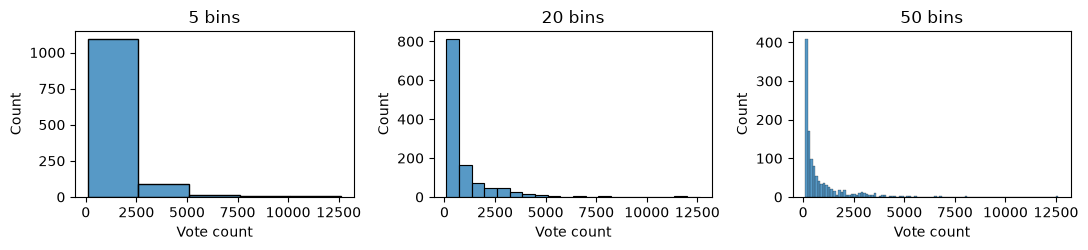

In [ ]:
shown = movies_df["vote_count"]

titles = ["5 bins", "20 bins", "100 bins"]

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))

for ax, bins, title in zip(axes, (5, 20, 100), titles):
    sns.histplot(shown, bins=bins, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Vote count")

plt.tight_layout()
plt.show()

The `vote_count` distribution is strongly right-skewed. Most movies
have relatively few votes, while a small number of highly voted movies
form a long right tail.

This is also visible in the summary statistics, the mean vote count
(936.35) is much larger than the median (378), while the maximum reaches
12616 votes.

## 2.3 Credits Dataset

In [53]:
print("=== CREDITS DATASET ===")

print("\nShape:")
print(credits_df.shape)

print("\nColumns:")
print(credits_df.columns.tolist())

print("\nData types:")
print(credits_df.dtypes)

print("\nFirst rows:")
display(credits_df.head(10))

print("=== Missing Values Summary ===")
missing_credits = credits_df.isna().sum()
display(missing_credits[missing_credits > 0].rename_axis("column").reset_index(name="missing_count")
)

print("=== ROLE COUNTS ===")

display(credits_df["role"].value_counts().rename_axis("role").reset_index(name="count"))


=== CREDITS DATASET ===

Shape:
(14252, 7)

Columns:
['movie_id', 'person_id', 'person_name', 'role', 'department', 'job', 'billing_order']

Data types:
movie_id           int64
person_id          int64
person_name       object
role              object
department        object
job               object
billing_order    float64
dtype: object

First rows:


,movie_id,person_id,person_name,role,department,job,billing_order
0,755898,1634181,Rich Lee,director,Directing,Director,NaN
1,755898,23430,Timur Bekmambetov,producer,Production,Producer,NaN
2,755898,964093,Patrick Aiello,producer,Production,Producer,NaN
3,755898,1076356,Christopher Probst,cinematographer,Camera,Director of Photography,NaN
4,755898,9778,Ice Cube,actor,None,None,0.0
5,755898,52605,Eva Longoria,actor,None,None,1.0
6,755898,9048,Clark Gregg,actor,None,None,2.0
7,755898,1632530,Iman Benson,actor,None,None,3.0
8,755898,60482,Henry Hunter Hall,actor,None,None,4.0
9,755898,90498,Devon Bostick,actor,None,None,5.0


=== Missing Values Summary ===


,column,missing_count
0,department,7191
1,job,7191
2,billing_order,7061


=== ROLE COUNTS ===


,role,count
0,actor,7191
1,producer,4573
2,director,1289
3,cinematographer,1199


## 2.4 Missingness pattern

=== MISSING VALUES BY ROLE ===


,department,job,billing_order
role,,,
actor,7191,7191,0
cinematographer,0,0,1199
director,0,0,1289
producer,0,0,4573


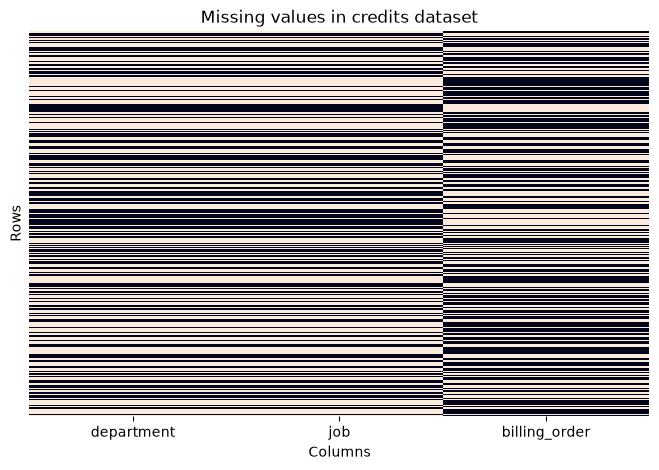

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
print("=== MISSING VALUES BY ROLE ===")

missing_by_role = (credits_df.groupby("role")[["department", "job", "billing_order"]].apply(lambda x: x.isna().sum()))

display(missing_by_role)

missing_cols = ["department", "job", "billing_order"]

plt.figure(figsize=(8, 5))

sns.heatmap(
    credits_df[missing_cols].isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing values in credits dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")

plt.show()


- `department` and `job` each have 7191 missing values,
  exactly equal to the number of actor rows.
- `billing_order` has 7061 missing values,
  exactly equal to the number of non-actor rows.
- with the heatmap we see that  the missing values are structural and depend on the role so when billing_order is present department and job are null and if department is null then job is null and actor is present
- There are fewer than six actor rows per movie on average maximum:
  7191 actor rows versus 7248 expected if every movie had six actors.


In [ ]:
##find mechanism
department_missing = credits_df["department"].isna()
job_missing = credits_df["job"].isna()
billing_missing = credits_df["billing_order"].isna()


print("=== Department missing by role ===")
print(pd.crosstab(credits_df["role"],department_missing,colnames=["missing"]))

print("\n=== Job missing by role ===")
print(pd.crosstab(credits_df["role"],job_missing,colnames=["missing"]))

print("\n=== Billing order missing by role ===")
print(pd.crosstab(credits_df["role"],billing_missing,colnames=["missing"]))


=== Department missing by role ===
missing          False  True 
role                         
actor                0   7191
cinematographer   1199      0
director          1289      0
producer          4573      0

=== Job missing by role ===
missing          False  True 
role                         
actor                0   7191
cinematographer   1199      0
director          1289      0
producer          4573      0

=== Billing order missing by role ===
missing          False  True 
role                         
actor             7191      0
cinematographer      0   1199
director             0   1289
producer             0   4573


- role = actor
→ department missing
→ job missing
→ billing_order present

- role = crew
→ department present
→ job present
→ billing_order missing

- the missing fields are determined by the observed role and correspond to attributes that are not applicable to that role so we are in the case of `MAR` mising at random

## 2.5 Finding impossible,ambigous and extreme values

In [64]:



release_date = pd.to_datetime(movies_df["release_date"],errors="coerce")


outside_period = ~release_date.between("2020-01-01","2025-12-31")

vote_below_threshold = movies_df["vote_count"] < 100

invalid_rating = ~movies_df["vote_average"].between(0,10)

duplicate_movie_ids = movies_df["id"].duplicated(keep=False)

empty_genres = movies_df["genre_ids"].apply(lambda x: len(x) == 0)


print("=== MOVIES: IMPOSSIBLE and  INVALID ===")

print("Release dates outside 2020-2025:",int(outside_period.sum()))

print("vote_count < 100:",int(vote_below_threshold.sum()))

print("vote_average outside [0, 10]:",int(invalid_rating.sum()))

print("Duplicated movie IDs:",int(duplicate_movie_ids.sum()))

print("Movies with empty genre list:",int(empty_genres.sum()))


print("\n=== CREDITS: INVALID and SUSPICIOUS ===")


allowed_roles = {"actor","director","producer","cinematographer"}

unknown_roles = ~credits_df["role"].isin(allowed_roles)

print("Unknown roles:",int(unknown_roles.sum()))

duplicate_credits = credits_df.duplicated(
    subset=["movie_id","person_id","role"],keep=False)

print("Duplicated (movie_id, person_id, role):",int(duplicate_credits.sum()))

=== MOVIES: IMPOSSIBLE and  INVALID ===
Release dates outside 2020-2025: 0
vote_count < 100: 0
vote_average outside [0, 10]: 0
Duplicated movie IDs: 0
Movies with empty genre list: 0

=== CREDITS: INVALID and SUSPICIOUS ===
Unknown roles: 0
Duplicated (movie_id, person_id, role): 0


In [60]:
print("\n=== MOVIES: EXTREME VALUES ===")

print("Highest vote counts:")

display(movies_df[["id", "title", "vote_count"]].sort_values("vote_count",ascending=False).head(10))

print("Highest popularity:")

display(movies_df[["id", "title", "popularity"]].sort_values("popularity",ascending=False).head(10))


=== MOVIES: EXTREME VALUES ===
Highest vote counts:


,id,title,vote_count
2,872585,Oppenheimer,12616
5,414906,The Batman,12609
35,508442,Soul,11785
3,361743,Top Gun: Maverick,11650
51,577922,Tenet,11590
73,646380,Don't Look Up,9741
86,508943,Luca,9149
95,38700,Bad Boys for Life,8910
44,615457,Nobody,8773
13,603692,John Wick: Chapter 4,8369


Highest popularity:


,id,title,popularity
0,755898,War of the Worlds,107.0445
2,872585,Oppenheimer,54.7098
3,361743,Top Gun: Maverick,49.5341
1,591634,False Positive,49.4602
4,1368166,The Housemaid,48.9580
8,1233413,Sinners,46.1146
5,414906,The Batman,44.3900
7,1011477,Karate Kid: Legends,42.9390
6,911430,F1,42.8465
11,575265,Mission: Impossible - The Final Reckoning,40.5748


this highset  count movies for example movie with 12616 votes is extreme compared with the median 378 they appear with a small frequency

In [68]:
actors_per_movie = (credits_df[credits_df["role"] == "actor"].groupby("movie_id").size())

print("Movies with more than 6 actors:",int((actors_per_movie > 6).sum()))

print("Movies with exactly 6 actors:",int((actors_per_movie == 6).sum()))

print("Movies with fewer than 6 actors:",int((actors_per_movie < 6).sum()))


Movies with more than 6 actors: 0
Movies with exactly 6 actors: 1189
Movies with fewer than 6 actors: 14


having movies with less than 6 actors is unusual because the scope acquired to have the top 6 actors it's not an error just the API may returned few casts for that movies

## 2.6 Time patterns

release_date
2020    211
2021    225
2022    225
2023    202
2024    176
2025    169
Name: count, dtype: int64

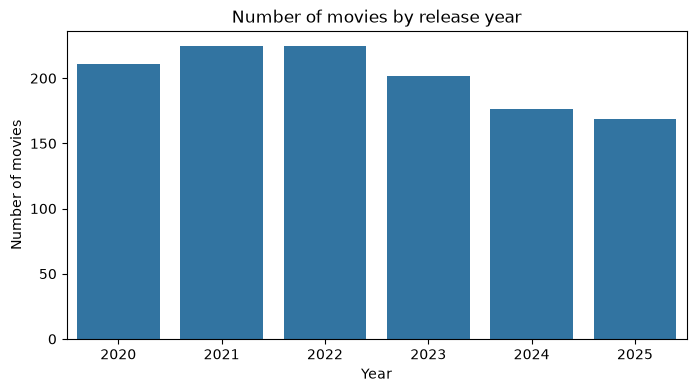

release_date
1      82
2      89
3     105
4      84
5      71
6      81
7      96
8     116
9     143
10    135
11    100
12    106
Name: movie_count, dtype: int64

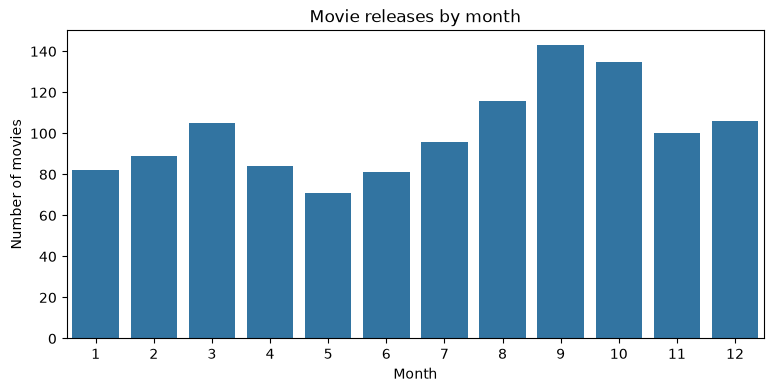

Missing months: PeriodIndex([], dtype='period[M]')


In [ ]:
release_date = pd.to_datetime(movies_df["release_date"], errors="coerce")

movies_by_year = (release_date.dt.year.value_counts().sort_index())

display(movies_by_year)
plt.figure(figsize=(8, 4))

sns.barplot(x=movies_by_year.index,y=movies_by_year.values)

plt.title("Number of movies by release year")
plt.xlabel("Year")
plt.ylabel("Number of movies")

plt.show()

movies_by_month = (release_date.dt.month.value_counts().sort_index())

display(movies_by_month.rename("movie_count"))

plt.figure(figsize=(9, 4))

sns.barplot(x=movies_by_month.index,y=movies_by_month.values)

plt.title("Movie releases by month")
plt.xlabel("Month")
plt.ylabel("Number of movies")

plt.show()

## to know if threre are any missing months in the dataset from 2020 to 2025
movies_by_period = (
    release_date
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

full_period = pd.period_range(
    "2020-01",
    "2025-12",
    freq="M"
)

missing_months = full_period.difference(
    movies_by_period.index
)

print("Missing months:", missing_months)

The dataset covers all years from 2020 to 2025.

The annual number of selected movies is relatively stable from 2020
to 2022, with 211 movies in 2020 and 225 in both 2021 and 2022.
The number then decreases to 202 movies in 2023, 176 in 2024 and
169 in 2025.

The monthly distribution is also not uniform. September has the
largest number of selected releases (143), followed by October (135),
while May has the lowest count (71).

## 3. Cleaning

In [95]:
movies_clean = movies_df.copy()
credits_clean = credits_df.copy()
DECISIONS = []

## convert release_date to datetime format insteas of object
movies_clean["release_date"] = pd.to_datetime(movies_clean["release_date"],errors="coerce")
print(movies_clean["release_date"].isna().sum())

DECISIONS.append(("convert release_date","needed for chronological analysis",len(movies_clean)))
credits_clean.duplicated(subset=["movie_id", "person_id", "role"]).sum() ## it's 0 so no duplicates and no action to dod 

DECISIONS.append((
    "There is noimpossible movies so there is no need to remove any movies",
    "release date, vote threshold or rating violates acquisition rules",
    
))


structural_missing = (
    credits_clean["department"].isna()
    | credits_clean["job"].isna()
    | credits_clean["billing_order"].isna()
)

DECISIONS.append((
    "keep structural missing values",
    "missingness is determined by role and means not applicable",
    int(structural_missing.sum())
))


0


In [99]:

actor_count = (credits_clean[credits_clean["role"] == "actor"].groupby("movie_id").size())

movies_clean["actor_count"] = (movies_clean["id"].map(actor_count).fillna(0).astype(int))

movies_clean["less_than_6_actors"] = (movies_clean["actor_count"] < 6)
DECISIONS.append((
    "flag movies with fewer than 6 actors",
    "fewer than 6 actors is unusual but can be valid in TMDB",
    int(movies_clean["less_than_6_actors"].sum())
))
display(movies_clean.head())


for role in [
    "director",
    "producer",
    "cinematographer"
]:

    ids = credits_clean.loc[credits_clean["role"] == role,"movie_id"].unique()
    movies_clean[f"has_{role}"] = (movies_clean["id"].isin(ids))

movies_clean["complete_selected_credits"] = (
    ~movies_clean["less_than_6_actors"]
    & movies_clean["has_director"]
    & movies_clean["has_producer"]
    & movies_clean["has_cinematographer"]
)
DECISIONS.append((
    "flag incomplete selected credits",
    "some movies may not contain all roles required for collaboration analysis",
    int((~movies_clean["complete_selected_credits"]).sum())
))



,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity,has_director,has_producer,has_cinematographer,actor_count,less_than_6_actors,complete_selected_credits
0,755898,War of the Worlds,War of the Worlds,2025-07-29,"[878, 53]",en,1160,4.034,107.0445,True,True,True,6,False,True
1,591634,False Positive,False Positive,2021-06-18,"[27, 9648, 53]",en,204,5.556,49.4602,True,True,True,6,False,True
2,872585,Oppenheimer,Oppenheimer,2023-07-19,"[18, 36]",en,12616,8.022,54.7098,True,True,True,6,False,True
3,361743,Top Gun: Maverick,Top Gun: Maverick,2022-05-21,"[28, 18]",en,11650,8.158,49.5341,True,True,True,6,False,True
4,1368166,The Housemaid,The Housemaid,2025-12-18,"[9648, 53]",en,3163,7.251,48.9580,True,True,True,6,False,True
